# Optional practice · Metrics and NumPy

Supplementary material, not the current 120-minute route. Use SecondLab.ipynb for NumPy + homework preparation, then PerceptronLab.ipynb for Part B.

# From predictions to evidence
**Neural Networks 2026 · Student companion · 9 October 2026**

## Goal
Turn predictions into meaningful measurements. Use NumPy masks, implement binary
classification metrics, compare Python and NumPy fairly, and connect matrices to linear systems.

**Optional topics:** recap → masks → confusion matrix → metrics → thresholds
→ performance → linear systems → Homework 1. The tree challenge is an optional extension.

**What you will write:** E1 counts, E2 metrics, E3 vectorized accuracy, E4 a tiny
plain-Python matrix operation; E5 tree traversal is optional. Each unfinished exercise
prints **NOT ATTEMPTED**, never a fake pass. Running all cells is safe before attempting them.

## Setup
Use the repository environment: `python -m pip install -r requirements-lab02.txt`.
Open this notebook with its Python kernel. In Colab, upload this file and run
`%pip install numpy matplotlib scikit-learn` only if imports are missing. CPU is enough.
All examples are small, synthetic, and included here; running downloads no datasets.

The official [NumPy exercises](../01_NumPy/02_Exercitii_NumPy.ipynb) and
[Homework 1](../01_NumPy/03_Tema_1.ipynb) remain the course requirements. This is a guided companion.

In [1]:
import sys
import timeit
from statistics import median
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
BLUE, ORANGE = "#1768ac", "#c76319"
print(f"Python {sys.version.split()[0]} · NumPy {np.__version__}")

Python 3.13.5 · NumPy 2.5.3


## Steps
### 1 · Predict the shape before running (8 min)
A batch has **rows = examples, columns = features**. For `X.shape == (3, 2)` and
`w.shape == (2,)`, what is the shape of `X @ w`? What does `axis=0` reduce?

This is the bridge to Course 2: a linear classifier computes a score and applies a threshold.
Weights below are hand chosen, not trained. A score is not automatically a probability.

In [2]:
X = np.array([[1., 0.], [0., 1.], [2., 1.]])
w = np.array([2., -1.])
bias = -0.5
scores_from_features = X @ w + bias
predictions = (scores_from_features >= 0).astype(int)
print("scores:", scores_from_features, "shape:", scores_from_features.shape)
print("predictions:", predictions)
print("feature means:", X.mean(axis=0))
assert scores_from_features.shape == (3,)

scores: [ 1.5 -1.5  2.5] shape: (3,)
predictions: [1 0 1]
feature means: [1.         0.66666667]


### 2 · A Boolean mask is a question asked of every row (10 min)
Imagine a spam filter: **1 = spam**, **0 = ordinary mail**. Each prediction and label
must refer to the same message. These are the ten examples from the official NumPy lab.

Read `actual == 1` as “which messages really are spam?”. Use `&` and parentheses for
array conditions; Python's `and` is for single truth values. A Boolean sum counts `True` entries.

In [3]:
actual = np.array([1, 1, 1, 1, 0, 0, 1, 0, 0, 0])
predicted = np.array([1, 1, 1, 0, 1, 0, 1, 1, 0, 0])
print("message:  ", np.arange(1, 11))
print("actual:   ", actual)
print("predicted:", predicted)
print("really spam:", actual == 1)
print("missed spam:", (actual == 1) & (predicted == 0))
print("missed count:", np.count_nonzero((actual == 1) & (predicted == 0)))
assert actual.shape == predicted.shape == (10,)

message:   [ 1  2  3  4  5  6  7  8  9 10]
actual:    [1 1 1 1 0 0 1 0 0 0]
predicted: [1 1 1 0 1 0 1 1 0 0]
really spam: [ True  True  True  True False False  True False False False]
missed spam: [False False False  True False False False False False False]
missed count: 1


### 3 · Confusion matrix: four kinds of outcome (17 min)
First classify messages **4, 5 and 6 by hand**. “Positive” means predicted spam;
“true” means the prediction was correct.

| | Predicted 0 | Predicted 1 |
|---|---|---|
| Actual 0 | TN: delivered ordinary mail | FP: ordinary mail blocked |
| Actual 1 | FN: spam delivered | TP: spam blocked |

**Convention throughout:** rows = actual, columns = predicted; class order `[0, 1]`.
`confusion_matrix(...).ravel()` yields **TN, FP, FN, TP**. Our exercise function returns
**TP, FP, FN, TN**, as requested in the original lab.

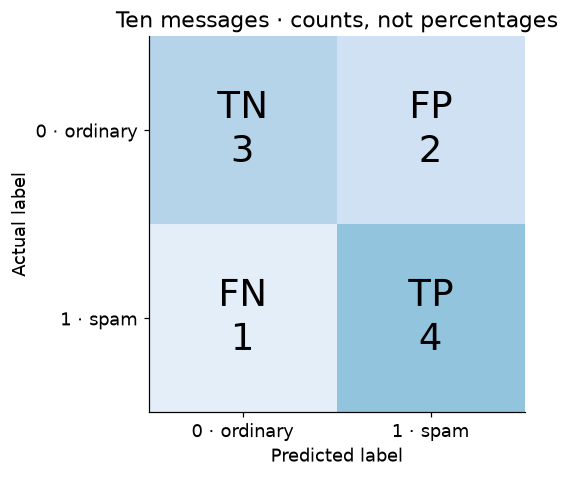

In [4]:
cm = confusion_matrix(actual, predicted, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=len(actual))
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, f"{[['TN', 'FP'], ['FN', 'TP']][i][j]}\n{value}",
            ha="center", va="center", fontsize=24)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["0 · ordinary", "1 · spam"],
       yticklabels=["0 · ordinary", "1 · spam"], xlabel="Predicted label",
       ylabel="Actual label", title="Ten messages · counts, not percentages")
fig.tight_layout(); plt.show()

**E1 — Implement the four counts (7 minutes).** Use Boolean masks and reductions,
without a Python loop. Inputs are nonempty one-dimensional binary arrays of the same shape.
Return ordinary integers in the order **TP, FP, FN, TN**. Replace `return None`.

In [5]:
def counts_numpy(gt, pred):
    # TODO: four masks, four counts
    return None

result = counts_numpy(actual, predicted)
if result is None:
    print("E1: NOT ATTEMPTED")
else:
    assert tuple(result) == (4, 2, 1, 3), result
    assert sum(result) == len(actual)
    print("E1: example passed — now try the corner cases in Checks.")

E1: NOT ATTEMPTED


### 4 · Which mistakes matter? (20 min)
- **Accuracy** = correct / all = `(TP + TN) / N`.
- **Precision** = correct spam flags / all spam flags = `TP / (TP + FP)`.
- **Recall** = found spam / all actual spam = `TP / (TP + FN)`.
- **F1** = `2*TP / (2*TP + FP + FN)`; it ignores true negatives.

For the ten messages: accuracy **0.70**, precision **2/3**, recall **0.80**, F1 **8/11**.
False positives lose ordinary mail; false negatives let spam through. Neither a threshold
nor a metric can choose those costs for us.

**E2 — Return a dictionary with `accuracy`, `precision`, `recall`, `f1`.** Use E1's counts.
For this lab, define a ratio with zero denominator as **0.0** (the same explicit policy
as `zero_division=0` in scikit-learn). An undefined ratio is not evidence of good performance.

In [6]:
def metrics_numpy(gt, pred):
    # TODO: use counts_numpy. Inputs follow the same contract as E1.
    return None

metrics = metrics_numpy(actual, predicted)
if metrics is None:
    print("E2: NOT ATTEMPTED")
else:
    for key, expected in dict(accuracy=.7, precision=2/3, recall=.8, f1=8/11).items():
        assert np.isclose(metrics[key], expected), (key, metrics[key])
    print(metrics)

E2: NOT ATTEMPTED


### 5 · The 99% accuracy trap (7 min)
A synthetic inbox has 99 ordinary messages and 1 spam message. The classifier always
says “ordinary”. **Before running:** predict accuracy, spam recall and spam F1.

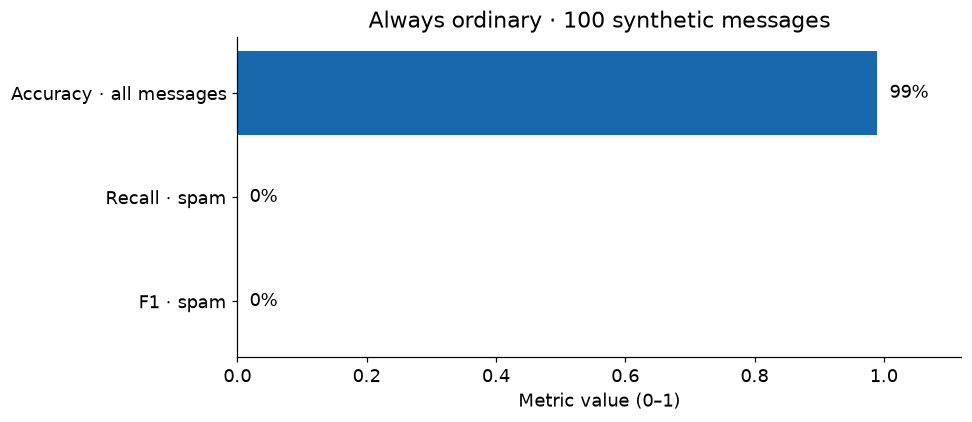

Confusion matrix: [[99, 0], [1, 0]]


In [7]:
rare_actual = np.array([0] * 99 + [1])
rare_predicted = np.zeros(100, dtype=int)
values = [accuracy_score(rare_actual, rare_predicted),
          recall_score(rare_actual, rare_predicted, zero_division=0),
          f1_score(rare_actual, rare_predicted, zero_division=0)]
fig, ax = plt.subplots()
bars = ax.barh(["Accuracy · all messages", "Recall · spam", "F1 · spam"], values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in values], padding=8)
ax.set(xlim=(0, 1.12), xlabel="Metric value (0–1)", title="Always ordinary · 100 synthetic messages")
ax.invert_yaxis(); fig.tight_layout(); plt.show()
print("Confusion matrix:", confusion_matrix(rare_actual, rare_predicted, labels=[0, 1]).tolist())

### 6 · Move the threshold; watch the mistakes change (12 min)
Same ten labels, now with hand-made scores in `[0, 1]`. These scores are **not calibrated
probabilities**. Predict spam when `score >= threshold`. The initial threshold reproduces
our original predictions exactly.

Lowering a threshold cannot decrease recall on a fixed dataset, but **precision need not
change monotonically**. Ask: which message changes next? What becomes an FP or FN?
The animation below works in the HTML export; the static chart remains available everywhere.

Use these examples to understand the mechanism. Choose a real operating threshold on a
validation set; keep the test set untouched for final evaluation.

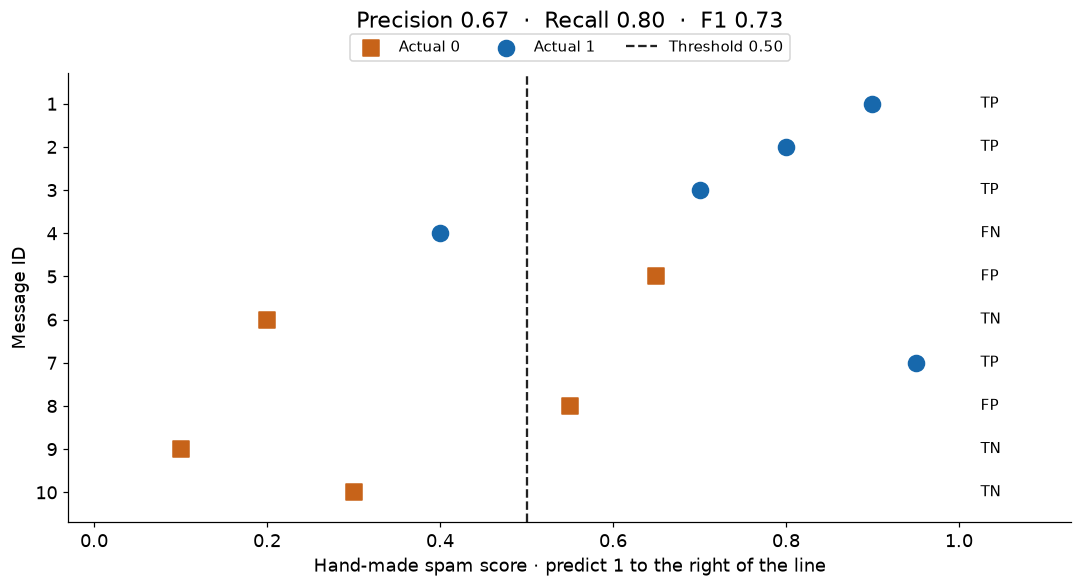

In [8]:
spam_scores = np.array([.90, .80, .70, .40, .65, .20, .95, .55, .10, .30])
assert np.array_equal((spam_scores >= .5).astype(int), predicted)

def draw_threshold(ax, threshold):
    ax.clear()
    pred = (spam_scores >= threshold).astype(int)
    for label, marker, color in [(0, "s", ORANGE), (1, "o", BLUE)]:
        indices = np.flatnonzero(actual == label)
        ax.scatter(spam_scores[indices], indices + 1, s=110, marker=marker,
                   color=color, label=f"Actual {label}")
    for i, (s, a, p) in enumerate(zip(spam_scores, actual, pred), 1):
        outcome = {(0, 0): "TN", (0, 1): "FP", (1, 0): "FN", (1, 1): "TP"}[int(a), int(p)]
        ax.text(1.025, i, outcome, va="center", fontsize=10)
    ax.axvline(threshold, color="#222222", linestyle="--", label=f"Threshold {threshold:.2f}")
    ax.set(xlim=(-.03, 1.13), ylim=(10.7, .3), yticks=range(1, 11),
           xlabel="Hand-made spam score · predict 1 to the right of the line", ylabel="Message ID")
    p = precision_score(actual, pred, zero_division=0)
    r = recall_score(actual, pred, zero_division=0)
    f = f1_score(actual, pred, zero_division=0)
    ax.set_title(f"Precision {p:.2f}  ·  Recall {r:.2f}  ·  F1 {f:.2f}", pad=30)
    ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.01), ncol=3, fontsize=10)

fig, ax = plt.subplots(figsize=(10, 5.5))
draw_threshold(ax, .5); fig.tight_layout(); plt.show()

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
fig.subplots_adjust(top=.78, bottom=.14, left=.09, right=.95)
thresholds = np.round(np.linspace(0, 1, 21), 2)
animation = FuncAnimation(fig, lambda t: draw_threshold(ax, t), frames=thresholds,
                          interval=550, repeat=False)
plt.close(fig)
display(HTML(animation.to_jshtml(default_mode="once")))

### 7 · Correct first; fast second (10 min)
**E3 — Vectorize accuracy.** Complete `accuracy_vectorized` using one comparison
and one reduction. The comparison below times the same operation on the same input,
without counting data generation, conversion, plotting or printing. We report the median
of five repeats; the machine and array size affect the outcome. `np.vectorize` is not a shortcut
to native vectorization: it primarily wraps a Python loop.

In [10]:
def accuracy_loop(gt, pred):
    correct = 0
    for a, p in zip(gt, pred):
        correct += int(a == p)
    return correct / len(gt)

def accuracy_vectorized(gt, pred):
    # TODO: one array comparison and reduction
    return None

big_actual = np.tile(actual, 10_000)  # 100,000 elements; bounded classroom experiment
big_predicted = np.tile(predicted, 10_000)
if accuracy_vectorized(actual, predicted) is None:
    print("E3: NOT ATTEMPTED — benchmark runs after you implement it.")
else:
    assert np.isclose(accuracy_vectorized(big_actual, big_predicted),
                      accuracy_loop(big_actual, big_predicted))
    for name, fn in [("Python loop", accuracy_loop), ("NumPy", accuracy_vectorized)]:
        fn(big_actual, big_predicted)  # warm-up; outside measured region
        times = timeit.repeat(lambda: fn(big_actual, big_predicted), repeat=5, number=3)
        print(f"{name}: median {median(times)/3*1000:.3f} ms per call")

E3: NOT ATTEMPTED — benchmark runs after you implement it.


### 8 · A matrix is a transformation; a system asks for its input (20 min)
Two ticket bundles cost 7 and 8 units. Let `x` be an adult ticket price and `y` a child ticket price:

`2x + y = 7` and `x + 2y = 8` → `A @ [x, y] = [7, 8]`.

Each equation is a line; the intersection satisfies both. Solving means finding the input
that a transformation sends to a chosen output. Determinant zero means information was
collapsed: there may be **no solution or infinitely many**, not a unique inverse.

The library call below is a classroom reference. **Homework 1 requires plain Python lists,
without NumPy or a linear algebra framework.** It asks for a different, 3×3 system.

Solution: [2. 3.] determinant: 2.9999999999999996
Check A @ solution: [7. 8.]


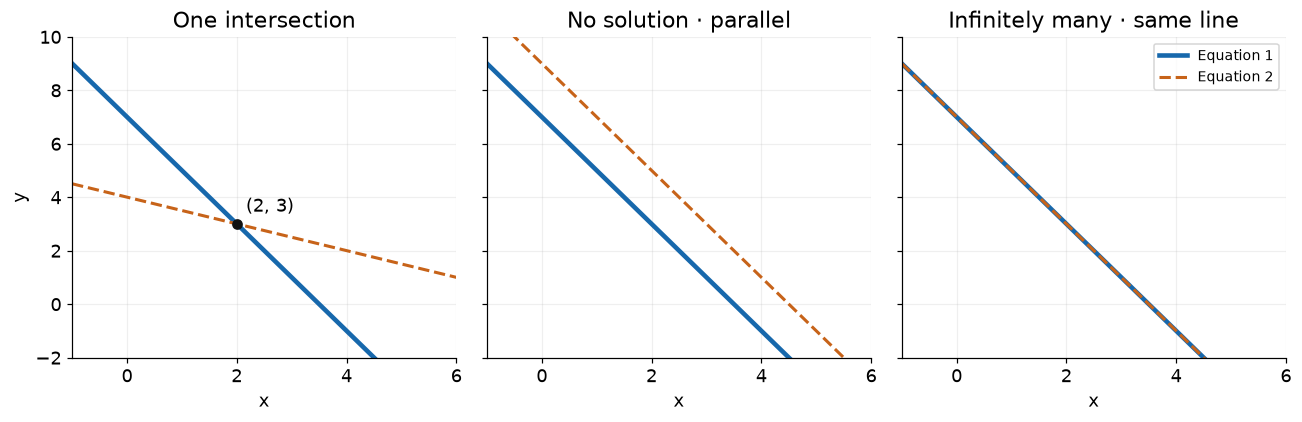

In [11]:
A = np.array([[2., 1.], [1., 2.]])
B = np.array([7., 8.])
solution = np.linalg.solve(A, B)
assert np.allclose(A @ solution, B)
print("Solution:", solution, "determinant:", np.linalg.det(A))
print("Check A @ solution:", A @ solution)

x = np.linspace(-1, 6, 120)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
examples = [("One intersection", (7-2*x), (8-x)/2),
            ("No solution · parallel", 7-2*x, 9-2*x),
            ("Infinitely many · same line", 7-2*x, 7-2*x)]
for ax, (title, y1, y2) in zip(axes, examples):
    ax.plot(x, y1, color=BLUE, label="Equation 1", linewidth=3)
    ax.plot(x, y2, color=ORANGE, linestyle="--", label="Equation 2", linewidth=2)
    ax.set(title=title, xlabel="x", xlim=(-1, 6), ylim=(-2, 10))
    ax.grid(alpha=.2)
axes[0].scatter(*solution, color="#111111", zorder=4)
axes[0].annotate("(2, 3)", solution, xytext=(6, 8), textcoords="offset points")
axes[0].set_ylabel("y"); axes[2].legend(fontsize=9)
fig.tight_layout(); plt.show()

**E4 — Plain Python warm-up.** Implement `matvec_2x2` for a 2×2 nested list and
a length-2 vector, with no NumPy inside the function. Then check the ticket prices `[2, 3]`.
On paper, write the 2×2 determinant `ad − bc` and solve the system by Cramer's rule.
Why must `det != 0` before division? In the homework, replacing a column must not accidentally
mutate the original matrix: copying only the outer list leaves shared rows.

In [12]:
def matvec_2x2(matrix, vector):
    # TODO: return a list with two row dot products. Use standard Python only.
    return None

answer = matvec_2x2([[2, 1], [1, 2]], [2, 3])
if answer is None:
    print("E4: NOT ATTEMPTED")
else:
    assert answer == [7, 8], answer
    assert matvec_2x2([[1, 0], [0, 1]], [-2, 5]) == [-2, 5]
    print("E4: examples passed")

E4: NOT ATTEMPTED


### Optional · Why can two O(n) programs run at different speeds?
The newly published [ProgrammingChallenge.ipynb](01_Programming_challenge.ipynb) asks you to
benchmark tree sizes. In its public template, both methods labelled “fastest” and “second
fastest” currently call the recursive baseline; those names are placeholders, not evidence.

**E5 — Count every node, including the root**, with an explicit stack instead of recursion.
Assume a finite tree, no cycles and no shared subtrees. Compare results before timings.
Both methods visit every node: O(n) time. Python call overhead and tree shape affect timing.
Do not cache a count and compare it with a fresh traversal without disclosing the extra assumption.

In [13]:
class Tree:
    def __init__(self, children=None):
        self.subrules = [] if children is None else children

    def len_recursive(self):
        return 1 + sum(child.len_recursive() for child in self.subrules)

def len_stack(tree):
    # TODO: maintain a stack and a count
    return None

tiny_tree = Tree([Tree(), Tree([Tree(), Tree()])])
if len_stack(tiny_tree) is None:
    print("E5: NOT ATTEMPTED (optional)")
else:
    assert len_stack(Tree()) == 1
    assert len_stack(tiny_tree) == tiny_tree.len_recursive() == 5
    print("E5: examples passed")

E5: NOT ATTEMPTED (optional)


## Checks
After E1 and E2, test **all-negative**, **all-positive**, **all-wrong** and **no-positive-prediction**
cases. `labels=[0, 1]` keeps the reference confusion matrix 2×2 even when only one class occurs.
The input contract excludes empty arrays and labels other than 0 and 1.

In [14]:
cases = [([0, 0], [0, 0]), ([1, 1], [1, 1]), ([0, 1], [1, 0]),
         ([1, 0], [0, 0]), ([0, 0], [1, 1]), (actual, predicted)]
if counts_numpy(actual, predicted) is None or metrics_numpy(actual, predicted) is None:
    print("Checks pending: complete E1 and E2 first.")
else:
    for gt, pred in cases:
        gt, pred = np.asarray(gt), np.asarray(pred)
        tn, fp, fn, tp = confusion_matrix(gt, pred, labels=[0, 1]).ravel()
        assert tuple(counts_numpy(gt, pred)) == (tp, fp, fn, tn)
        measured = metrics_numpy(gt, pred)
        reference = dict(accuracy=accuracy_score(gt, pred),
                         precision=precision_score(gt, pred, zero_division=0),
                         recall=recall_score(gt, pred, zero_division=0),
                         f1=f1_score(gt, pred, zero_division=0))
        for key, value in reference.items():
            assert np.isclose(measured[key], value), (gt, pred, key, measured, reference)
    print(f"All {len(cases)} reference cases passed.")

Checks pending: complete E1 and E2 first.


## Next Steps
### Homework 1 · before Lab 3
Open [Assignment1.ipynb](../01_NumPy/03_Tema_1.ipynb) and place [system.txt](../01_NumPy/system.txt) beside it.
Read the official statement for assessment details. Use **Python lists and standard Python;
no NumPy or linear algebra framework**. Deliver parsing (1 point), matrix/vector operations
(5), Cramer (1), and inverse/adjugate (3). Test `A @ solution = B` using your own matrix-vector
function; handle a zero determinant before division. The published deadline is **before Lab 3**;
confirm the submission channel with your teacher.

### Exit ticket (3 minutes, without running code)
1. Why does 99% accuracy not mean our rare spam detector works?
2. Can increasing a fixed-score classifier's threshold increase recall?
3. In `confusion_matrix(..., labels=[0, 1]).ravel()`, which position is FP?
4. What does a zero determinant tell you about a unique solution?

### Resources and provenance
- [Official Lab 2](https://github.com/Tensor-Reloaded/Neural-Networks-2026/tree/main/Lab02),
  reviewed 9 October 2026 at upstream commit `4dc46e1a`.
- [Published courses](https://sites.google.com/view/rbenchea/neural-networks): Course 1
  (ML concepts, linear algebra, NumPy) and Course 2 (perceptron). Publication does not prove
  every slide has already been taught.
- [3Blue1Brown: Essence of linear algebra](https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab):
  use chapters 3 (transformations), 6 (determinant) and 7 (inverse, column space, null space).
- [NumPy broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html),
  [scikit-learn confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html),
  [F1 score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).

The threshold scores, ticket example and exercises E4–E5 are teaching examples authored for
this companion. The ten binary labels/predictions and E1–E3 goals come from the official lab.